# 20260317 Feronia salinity time course sc 291 ~ 294 (new integrated seu 3 object, no suspicious cluster)  Cell Oracle
# WT-untreated vs fer4-untreated
This runs within the cell_oracle Conda environment

In [1]:
# Python
# Don't change anything here
import os
import sys
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns

In [2]:
# Set the working dir
# Change to your own directory
# NOTE: lab cluster path below -- change it to your own path
os.chdir("/resnick/groups/NolanLab/cchen/Feronia/analysis/")

In [3]:
# Check the conda env
# Don't change anything here
env_name = os.environ.get('CONDA_DEFAULT_ENV')
print(env_name)

cell_oracle


In [4]:
# Import and check CellOracle
# Don't change anything here
import celloracle as co
co.__version__

'0.20.0'

In [5]:
# Check scanpy version
# Don't change anything here
print(sc.__version__)

1.11.0


In [6]:
# visualization settings
# You can adjust this if you'd like
%config InlineBackend.figure_format = 'retina'
%matplotlib inline

plt.rcParams['figure.figsize'] = [6, 4.5]
plt.rcParams["savefig.dpi"] = 300


In [7]:
# Make sure that all R libraries are installed
# Don't change anything here
co.test_R_libraries_installation()

In [8]:
# Don't change anything here
# Read in an input neede by CellOracle
# NOTE: lab cluster path below -- change it to your own path
id2name = pd.read_table('/resnick/groups/NolanLab/shared_resources/source_files/celloracle_inputs/features.tsv.gz', 
                        compression='gzip', header=None)

In [9]:
id2name.head(n = 3)

,0,1,2
0,AT1G01010,NAC001,Gene Expression
1,AT1G01020,ARV1,Gene Expression
2,AT1G03987,AT1G03987,Gene Expression


In [10]:
# Load samples in h5ad format 
# Change the sample names and paths to match yours
# The raw RNA counts
# NOTE: lab cluster path below -- change it to your own path
my_sample = sc.read_h5ad("/resnick/groups/NolanLab/shared_resources/annotated_objects/h5ad/Feronia_salinity_timecourse_4S_20251226_seu3_sc291suspiciousClusterRemoved_RNA.h5ad")




In [11]:
# Check the observation
my_sample.obs.head(n = 3)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,...,pANN_0.25_0.15_464,DF.classifications_0.25_0.15_464,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype
AAACCCAAGGACTTCT_4,sc_291,2801.0,1473,2678.0,1418,123.0,91,0.071403,0.107105,7949.0,...,NaN,NA,NaN,NA,NaN,NA,4,Elongation,9,0
AAACCCAAGGTCGTGA_4,sc_291,14092.0,3995,13277.0,3834,815.0,453,0.262560,0.369004,9904.0,...,NaN,NA,NaN,NA,NaN,NA,3,Transition Domain,4,0
AAACCCAAGTGCACTT_4,sc_291,4888.0,2274,4596.0,2200,292.0,183,0.225041,0.327332,8348.0,...,NaN,NA,NaN,NA,NaN,NA,7,Transition Domain,4,0


In [12]:
my_sample.obs["orig.ident"].unique()

array(['sc_291', 'sc_292', 'sc_293', 'sc_294'], dtype=object)

In [13]:
# Subset the samples
subset_sample = my_sample[my_sample.obs["orig.ident"].isin(["sc_291", "sc_292", "sc_293", "sc_294"])]



In [14]:
subset_sample.obs["orig.ident"].unique()

array(['sc_291', 'sc_292', 'sc_293', 'sc_294'], dtype=object)

In [15]:
# Concatenate the samples
# Change the sample names to match yours
adata = subset_sample

In [16]:
# Check the original identity column
# Don't change anything here
adata.obs['orig.ident'].unique()

array(['sc_291', 'sc_292', 'sc_293', 'sc_294'], dtype=object)

In [17]:
# How many cells in each sample
# Don't change anything here
pd.Series(adata.obs['orig.ident']).value_counts()

sc_294    12714
sc_293    10911
sc_291    10744
sc_292    10295
Name: orig.ident, dtype: int64

In [18]:
# Creates a new column called 'mannitol' in adata.obs, copying values from the existing column orig.ident
# Change mannitol to your preferred group name
adata.obs['feronia']= adata.obs['orig.ident']

In [19]:
adata.obs['feronia'].unique()

array(['sc_291', 'sc_292', 'sc_293', 'sc_294'], dtype=object)

In [20]:
# Replace the mannitol column values with the treatments
# Change this to match your sample names, column names and treatments
adata.obs['feronia'] = adata.obs['feronia'].replace('sc_291', 'WT_untreated')
adata.obs['feronia'] = adata.obs['feronia'].replace('sc_292', 'fer4_untreated')
adata.obs['feronia'] = adata.obs['feronia'].replace('sc_293', 'WT_untreated')
adata.obs['feronia'] = adata.obs['feronia'].replace('sc_294', 'fer4_untreated')


In [21]:
# How many cells in each group
# Don't change anything here
adata.obs['feronia'].value_counts()

fer4_untreated    23009
WT_untreated      21655
Name: feronia, dtype: int64

In [24]:
# Check how many cells in each cell type
# Don't change anything here
pd.Series(adata.obs['time.celltype.anno.Li']).value_counts()

Proximal Lateral Root Cap                           8933
Elongation_Xylem Pole Pericycle                     3907
Transition Domain_Trichoblast                       3415
Elongation_Endodermis                               2540
Elongation_Procambium                               2383
Elongation_Cortex                                   2334
Proliferation Domain_Atrichoblast                   1902
Distal Columella                                    1730
Elongation_Trichoblast                              1696
Elongation_Atrichoblast                             1655
Transition Domain_Atrichoblast                      1268
Elongation_Phloem Pole Pericycle                    1247
Distal Lateral Root Cap                             1215
Proliferation Domain_Trichoblast                    1091
Maturation_Endodermis                                926
Transition Domain_Cortex                             856
Maturation_Trichoblast                               735
Elongation_Metaxylem           

In [25]:
#pd.Series(adata.obs['time.anno.Li']).value_counts()

In [26]:
# Add the column "time.celltype.anno.Li" that combines cell type and time (development stage) info
# Don't change anything here
#adata.obs['time.celltype.anno.Li'] = adata.obs['time.anno.Li'].astype(str) + "_" + adata.obs['celltype.anno.Li'].astype(str)

In [27]:
# Check how many cells in each time.cell type
# Don't change anything here
pd.Series(adata.obs['time.celltype.anno.Li']).value_counts()

Proximal Lateral Root Cap                           8933
Elongation_Xylem Pole Pericycle                     3907
Transition Domain_Trichoblast                       3415
Elongation_Endodermis                               2540
Elongation_Procambium                               2383
Elongation_Cortex                                   2334
Proliferation Domain_Atrichoblast                   1902
Distal Columella                                    1730
Elongation_Trichoblast                              1696
Elongation_Atrichoblast                             1655
Transition Domain_Atrichoblast                      1268
Elongation_Phloem Pole Pericycle                    1247
Distal Lateral Root Cap                             1215
Proliferation Domain_Trichoblast                    1091
Maturation_Endodermis                                926
Transition Domain_Cortex                             856
Maturation_Trichoblast                               735
Elongation_Metaxylem           

In [28]:
# Replace some of the time.celltype.anno.Li to remove the redundancy in the names
# Don't change anything here
#adata.obs['time.celltype.anno.Li'] = adata.obs['time.celltype.anno.Li'].replace(
#    'Proximal Lateral Root Cap_Lateral Root Cap', 'Proximal Lateral Root Cap')

#adata.obs['time.celltype.anno.Li'] = adata.obs['time.celltype.anno.Li'].replace(
#    'Distal Lateral Root Cap_Lateral Root Cap', 'Distal Lateral Root Cap')

#adata.obs['time.celltype.anno.Li'] = adata.obs['time.celltype.anno.Li'].replace(
#    'Distal Columella_Columella', 'Distal Columella')

#adata.obs['time.celltype.anno.Li'] = adata.obs['time.celltype.anno.Li'].replace(
#    'Proximal Columella_Columella', 'Proximal Columella')

In [29]:
#Check again time.celltype.anno.Li
# Don't change anything here
#pd.Series(adata.obs['time.celltype.anno.Li']).value_counts()

In [30]:
# Create a column "celltype.time.anno" that combines time.cell type and group/treatment info
# Change mannitol to your own column name
adata.obs['celltype.time.anno'] = adata.obs['time.celltype.anno.Li'].astype(str) + "_" + adata.obs['feronia'].astype(str)

In [31]:
# Check how many cells per celltype.time.anno
# Don't change anything here
pd.Series(adata.obs['celltype.time.anno']).value_counts()

Proximal Lateral Root Cap_fer4_untreated                     5315
Proximal Lateral Root Cap_WT_untreated                       3618
Transition Domain_Trichoblast_WT_untreated                   2047
Elongation_Xylem Pole Pericycle_WT_untreated                 2001
Elongation_Xylem Pole Pericycle_fer4_untreated               1906
                                                             ... 
Transition Domain_Phloem Pole Pericycle_WT_untreated            3
Transition Domain_Protophloem_WT_untreated                      2
Proliferation Domain_Phloem Pole Pericycle_fer4_untreated       2
Proliferation Domain_Phloem Pole Pericycle_WT_untreated         2
Proliferation Domain_Protoxylem_WT_untreated                    1
Name: celltype.time.anno, Length: 90, dtype: int64

In [32]:
# Don't change anything here
adata.layers["raw_count"] = adata.X.copy()

In [33]:
os.getcwd()

'/resnick/groups/NolanLab/cchen/Feronia/analysis'

In [34]:
# First, make a clean copy of raw.var without the problematic column
clean_var = adata.raw.var.drop(columns="_index")

# Then create a new raw AnnData object using adata.raw.X and cleaned var
import anndata as ad
adata.raw = ad.AnnData(X=adata.raw.X, var=clean_var)


In [35]:
# Save input for CellOracle
# Change it to your object name
# Comment it out after saving for safety
adata.write_h5ad("CellOracle/CellOracle_input/20250509_4S_feronia_salinity_time_course_untreated_celloracle_input.h5ad")


... storing 'orig.ident' as categorical
... storing 'DF.classifications_0.25_0.15_943' as categorical
... storing 'celltype.ID' as categorical
... storing 'timezone.ID' as categorical
... storing 'celltype.ID.P' as categorical
... storing 'timezone.ID.P' as categorical
... storing 'Rad.ID' as categorical
... storing 'Long.ID' as categorical
... storing 'Rad.ID.P' as categorical
... storing 'Long.ID.P' as categorical
... storing 'SCT_snn_res.5' as categorical
... storing 'seucluster.celltype.ID' as categorical
... storing 'seucluster.celltype.ID.P' as categorical
... storing 'seucluster.timezone.ID' as categorical
... storing 'seucluster.timezone.ID.P' as categorical
... storing 'seucluster.Rad.ID' as categorical
... storing 'seucluster.Rad.ID.P' as categorical
... storing 'seucluster.Long.ID' as categorical
... storing 'seucluster.Long.ID.P' as categorical
... storing 'predicted.id' as categorical
... storing 'time.celltype.anno' as categorical
... storing 'celltype.anno' as categorica

In [36]:
# Read in the h5ad object
# Change it to your object name
ADATA = sc.read_h5ad('CellOracle/CellOracle_input/20250509_4S_feronia_salinity_time_course_untreated_celloracle_input.h5ad')

In [37]:
# Check ADATA
# Don't change anything here
ADATA

AnnData object with n_obs × n_vars = 44664 × 29411
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spliced_RNA', 'nFeature_spliced_RNA', 'nCount_unspliced_RNA', 'nFeature_unspliced_RNA', 'percent.mt', 'percent.cp', 'nCount_SCT', 'nFeature_SCT', 'nCount_spliced_SCT', 'nFeature_spliced_SCT', 'nCount_unspliced_SCT', 'nFeature_unspliced_SCT', 'pANN_0.25_0.15_943', 'DF.classifications_0.25_0.15_943', 'celltype.ID', 'timezone.ID', 'celltype.cor', 'timezone.cor', 'celltype.pvalue', 'timezone.pvalue', 'celltype.ID.P', 'timezone.ID.P', 'celltype.cor.P', 'timezone.cor.P', 'celltype.pvalue.P', 'timezone.pvalue.P', 'Rad.ID', 'Long.ID', 'Rad.cor', 'Long.cor', 'Rad.pvalue', 'Long.pvalue', 'Rad.ID.P', 'Long.ID.P', 'Rad.cor.P', 'Long.cor.P', 'Rad.pvalue.P', 'Long.pvalue.P', 'SCT_snn_res.5', 'seurat_clusters', 'seucluster.celltype.cor', 'seucluster.celltype.pvalue', 'seucluster.celltype.ID', 'seucluster.celltype.cor.P', 'seucluster.celltype.pvalue.P', 'seucluster.celltype.ID.P', 'seucluste

In [38]:
ADATA.obs.head(5)

,orig.ident,nCount_RNA,nFeature_RNA,nCount_spliced_RNA,nFeature_spliced_RNA,nCount_unspliced_RNA,nFeature_unspliced_RNA,percent.mt,percent.cp,nCount_SCT,...,pANN_0.25_0.15_526,DF.classifications_0.25_0.15_526,pANN_0.25_0.15_726,DF.classifications_0.25_0.15_726,integrated_snn_res.0.5,time.anno.Li,celltype.anno.Li,genotype,feronia,celltype.time.anno
AAACCCAAGGACTTCT_4,sc_291,2801.0,1473,2678.0,1418,123.0,91,0.071403,0.107105,7949.0,...,NaN,NA,NaN,NA,4,Elongation,9,0,WT_untreated,Elongation_Procambium_WT_untreated
AAACCCAAGGTCGTGA_4,sc_291,14092.0,3995,13277.0,3834,815.0,453,0.262560,0.369004,9904.0,...,NaN,NA,NaN,NA,3,Transition Domain,4,0,WT_untreated,Transition Domain_Trichoblast_WT_untreated
AAACCCAAGTGCACTT_4,sc_291,4888.0,2274,4596.0,2200,292.0,183,0.225041,0.327332,8348.0,...,NaN,NA,NaN,NA,7,Transition Domain,4,0,WT_untreated,Transition Domain_Trichoblast_WT_untreated
AAACCCAAGTGTTCCA_4,sc_291,11840.0,3987,11305.0,3864,535.0,344,0.430743,0.329392,9877.0,...,NaN,NA,NaN,NA,22,Elongation,6,0,WT_untreated,Elongation_Endodermis_WT_untreated
AAACCCAGTCTCGGGT_4,sc_291,3564.0,1622,3409.0,1568,155.0,105,0.056117,0.084175,8159.0,...,NaN,NA,NaN,NA,5,Elongation,11,0,WT_untreated,Elongation_Phloem Pole Pericycle_WT_untreated


In [39]:
# Load TF info
# Don't change anything here
# NOTE: lab cluster path below -- change it to your own path
wanted_TFs = pd.read_csv("/resnick/groups/NolanLab/shared_resources/source_files/celloracle_inputs/Kay_TF_thalemine_annotations.csv")

In [40]:
# Check TF table
# Don't change anything here
wanted_TFs.head()

,GeneID,Name,Description
0,AT1G01010,NAC001,NAC domain containing protein 1
1,AT1G01030,NGA3,AP2/B3-like transcriptional factor family protein
2,AT1G01060,LHY,Homeodomain-like superfamily protein
3,AT1G01250,AT1G01250,Integrase-type DNA-binding superfamily protein
4,AT1G01260,AT1G01260,basic helix-loop-helix (bHLH) DNA-binding supe...


In [41]:
# Load base_GRN
# Don't change anything here
import pickle

# NOTE: lab cluster path below -- change it to your own path
with open("/resnick/groups/NolanLab/shared_resources/source_files/celloracle_inputs/base_GRN_TG_to_TF_dictionary.pkl", 'rb') as file_handle:
    TG_to_TF_dictionary = pickle.load(file_handle)

In [43]:
# Read in the DE files
# Note!! This is based on the DE result with the wrong direction! 
# But since we only need DE gene names here, the direction doesn't affect CellOracle result
# I've checked that the wrong direction sig_de_fil.csv has identical gene list as the correct direciton one.
# So there's no need to rerun this CellOracle analysis
DE = pd.read_csv("./muscat_result/20260317_salinity_timecourse_useDateT_noSuspiciousClusters/group_timecelltypeannoLi/fer_4-WT/sig_de_fil.csv", index_col=None)

In [44]:
# Check DE table
# Don't change anything here
DE.head(n = 5)

,Unnamed: 0,gene,cluster_id,sc_292.cpm,sc_294.cpm,sc_291.cpm,sc_293.cpm,sc_292.frq,sc_294.frq,sc_291.frq,...,p_val,p_adj.loc,p_adj.glb,contrast,gene.y,non,TF_Name,Description,up_dn_label,clust_up_dn
0,1,AT3G51550,Elongation_Cortex,0.165,0.362,288.0,323.0,0.00322,0.00164,0.830,...,4.050000e-230,8.440000e-226,2.910000e-224,fer_4-WT,FER,Gene Expression,NaN,NaN,Down,Elongation_Cortex_Down
1,2,AT3G51550,Elongation_Phloem Pole Pericycle,0.000,0.267,173.0,169.0,0.00000,0.00305,0.711,...,7.280000e-190,1.510000e-185,2.620000e-184,fer_4-WT,FER,Gene Expression,NaN,NaN,Down,Elongation_Phloem Pole Pericycle_Down
2,3,AT3G51550,Elongation_Trichoblast,0.000,1.690,228.0,297.0,0.00000,0.01380,0.916,...,6.680000e-177,1.400000e-172,1.600000e-171,fer_4-WT,FER,Gene Expression,NaN,NaN,Down,Elongation_Trichoblast_Down
3,4,AT3G51550,Proliferation Domain_Trichoblast,0.000,0.669,80.2,71.9,0.00000,0.00439,0.604,...,7.700000e-170,1.570000e-165,1.380000e-164,fer_4-WT,FER,Gene Expression,NaN,NaN,Down,Proliferation Domain_Trichoblast_Down
4,5,AT3G51550,Elongation_Endodermis,0.000,0.111,240.0,252.0,0.00000,0.00141,0.816,...,3.080000e-151,6.510000e-147,4.430000e-146,fer_4-WT,FER,Gene Expression,NaN,NaN,Down,Elongation_Endodermis_Down


In [45]:
# Check DE length
# Don't change anything here
len(DE['gene'].unique())

5466

## Prepare the cell type lists
They will be used to filter the cell types

In [46]:
# cortex
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
cortex_names = vc[vc.index.str.contains("cortex", case=False, na=False)]
cortex_names.index.tolist()

['Elongation_Cortex',
 'Transition Domain_Cortex',
 'Maturation_Cortex',
 'Proliferation Domain_Cortex']

In [47]:
# endodermis
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
endodermis_names = vc[vc.index.str.contains("endodermis", case=False, na=False)]
endodermis_names.index.tolist()

['Elongation_Endodermis',
 'Maturation_Endodermis',
 'Proliferation Domain_Endodermis',
 'Transition Domain_Endodermis']

In [48]:
# trichoblast (need to exclude atrichoblast)
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
trichoblast_names = vc[vc.index.str.contains("trichoblast", case=False, na=False) & ~vc.index.str.contains("atrichoblast", case=False, na=False)]
trichoblast_names.index.tolist()

['Transition Domain_Trichoblast',
 'Elongation_Trichoblast',
 'Proliferation Domain_Trichoblast',
 'Maturation_Trichoblast']

In [49]:
# atrichoblast
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
atrichoblast_names = vc[vc.index.str.contains("atrichoblast", case=False, na=False)]
atrichoblast_names.index.tolist()

['Proliferation Domain_Atrichoblast',
 'Elongation_Atrichoblast',
 'Transition Domain_Atrichoblast',
 'Maturation_Atrichoblast']

In [50]:
# pericycle
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
pericycle_names = vc[vc.index.str.contains("pericycle", case=False, na=False)]
pericycle_names.index.tolist()

['Elongation_Xylem Pole Pericycle',
 'Elongation_Phloem Pole Pericycle',
 'Transition Domain_Xylem Pole Pericycle',
 'Proliferation Domain_Xylem Pole Pericycle',
 'Maturation_Xylem Pole Pericycle',
 'Maturation_Phloem Pole Pericycle',
 'Transition Domain_Phloem Pole Pericycle',
 'Proliferation Domain_Phloem Pole Pericycle']

In [51]:
#phloem  (need to exclude pericycle)
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
phloem_names = vc[vc.index.str.contains("phloem", case=False, na=False) & ~vc.index.str.contains("pericycle", case=False, na=False)]
phloem_names.index.tolist()

['Elongation_Metaphloem & Companion Cell',
 'Elongation_Protophloem',
 'Transition Domain_Metaphloem & Companion Cell',
 'Proliferation Domain_Metaphloem & Companion Cell',
 'Maturation_Metaphloem & Companion Cell',
 'Transition Domain_Protophloem']

In [52]:
#xylem (need to exclude pericycle)
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
xylem_names = vc[vc.index.str.contains("xylem", case=False, na=False) & ~vc.index.str.contains("pericycle", case=False, na=False)]
xylem_names.index.tolist()

['Elongation_Metaxylem',
 'Elongation_Protoxylem',
 'Maturation_Protoxylem',
 'Transition Domain_Protoxylem',
 'Transition Domain_Metaxylem',
 'Proliferation Domain_Metaxylem',
 'Proliferation Domain_Protoxylem']

In [53]:
# procambium
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
procambium_names = vc[vc.index.str.contains("procambium", case=False, na=False)]
procambium_names.index.tolist()

['Elongation_Procambium',
 'Maturation_Procambium',
 'Transition Domain_Procambium',
 'Proliferation Domain_Procambium']

In [54]:
# lrc
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
lrc_names = vc[vc.index.str.contains("Lateral Root Cap", case=False, na=False)]
lrc_names.index.tolist()

['Proximal Lateral Root Cap', 'Distal Lateral Root Cap']

In [55]:
# columella
# Don't change anything here
vc = pd.Series(ADATA.obs['time.celltype.anno.Li']).value_counts()
columella_names = vc[vc.index.str.contains("columella", case=False, na=False)]
columella_names.index.tolist()

['Distal Columella', 'Proximal Columella']

In [56]:
# List the celltype.time.anno with only 1 count
# They have to be removed manualy in the cell right below because they'll cause error in CellOracle
# Don't change anything here
vc = ADATA.obs['celltype.time.anno'].value_counts()
vc[vc == 1]

Proliferation Domain_Protoxylem_WT_untreated    1
Name: celltype.time.anno, dtype: int64

In [57]:
# Important: You need to manually exclude (if any) the celltype.time.anno with only 1 count shown above!
# Examples (with ~) are in pericycle and procambium
# Change the lines with "~" (which is the NOT operator) to fit your samples. Remove them if there's nothing to exclude.
# 10 cell types in total

cortex = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(cortex_names.index.tolist()))]

endodermis = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(endodermis_names.index.tolist()))]

trichoblast = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(trichoblast_names.index.tolist()))]

atrichoblast = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(atrichoblast_names.index.tolist()))]

pericycle = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(pericycle_names.index.tolist()))]

phloem = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(phloem_names.index.tolist()))]

xylem = ADATA.obs.index[
    (~ADATA.obs['celltype.time.anno'].isin(['Proliferation Domain_Protoxylem_WT_untreated'])) & 
    (ADATA.obs['time.celltype.anno.Li'].isin(xylem_names.index.tolist()))]

procambium = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(procambium_names.index.tolist()))]

lrc = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(lrc_names.index.tolist()))]

columella = ADATA.obs.index[
    (ADATA.obs['time.celltype.anno.Li'].isin(columella_names.index.tolist()))]

In [58]:
# Check the number of cells in your samples
# Don't change anything here
print(len(cortex))
print(len(endodermis))
print(len(trichoblast))
print(len(atrichoblast))
print(len(pericycle))
print(len(phloem))
print(len(xylem))
print(len(procambium))
print(len(lrc))
print(len(columella))

4113
4050
6937
5203
6036
1307
1699
2846
10148
2299


In [59]:
# Build a dictionary to store the cells (barcodes) in each cell type
# Important: include only the cell types you want to analyze! Comment out or remove the unwanted cell types
celltypes = {
    'cortex':cortex,
    'endodermis':endodermis,
    'trichoblast':trichoblast,
    'atrichoblast':atrichoblast,
    'pericycle':pericycle, 
    'phloem':phloem,
    'xylem':xylem, 
    'procambium':procambium, 
    'lrc':lrc, 
    'columella':columella}

In [60]:
DE['cluster_id'].unique()

array(['Elongation_Cortex', 'Elongation_Phloem Pole Pericycle',
       'Elongation_Trichoblast', 'Proliferation Domain_Trichoblast',
       'Elongation_Endodermis', 'Transition Domain_Atrichoblast',
       'Distal Columella', 'Transition Domain_Cortex',
       'Proliferation Domain_Atrichoblast',
       'Elongation_Metaphloem & Companion Cell',
       'Elongation_Atrichoblast',
       'Transition Domain_Xylem Pole Pericycle', 'Maturation_Endodermis',
       'Distal Lateral Root Cap', 'Elongation_Protoxylem',
       'Maturation_Xylem Pole Pericycle', 'Proliferation Domain_Cortex',
       'Transition Domain_Metaphloem & Companion Cell',
       'Maturation_Procambium', 'Maturation_Atrichoblast',
       'Transition Domain_Procambium', 'Proximal Lateral Root Cap',
       'Elongation_Metaxylem', 'Maturation_Trichoblast',
       'Transition Domain_Endodermis', 'Transition Domain_Protoxylem',
       'Proliferation Domain_Endodermis', 'Maturation_Cortex',
       'Elongation_Procambium', 'Matura

## Run CellOracle

> **NOT USED IN THE PAPER.** This interactive loop was started but interrupted (it stopped in trichoblast). The published networks were built by the SLURM array script `…_slurmArray_run_celloracle_grn.py` from the input file saved above. This loop also read an earlier version of `sig_de_fil.csv` (cortex: 4,187 genes here vs 4,168 in the SLURM run), so its partial output differs from the published networks. Only the cells above this section are needed to reproduce the CellOracle input.

This script processes single-cell RNA-seq data to construct Gene Regulatory Networks (GRNs) for different cell types. It selects relevant genes, performs PCA and UMAP for dimensionality reduction, and initializes an Oracle object with raw RNA counts. KNN imputation refines the data, followed by GRN construction and filtering of significant interactions. Finally, it saves the network data, regulatory scores, and mapped gene names for further analysis. 

In [61]:
os.getcwd()

'/resnick/groups/NolanLab/cchen/Feronia/analysis'

In [62]:
# Change output dir
# NOTE: lab cluster path below -- change it to your own path
os.chdir('/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster')


FileNotFoundError: [Errno 2] No such file or directory: '/resnick/groups/NolanLab/cchen/Feronia/analysis/CellOracle/CellOracle_output/20260317_feronia_salinity_timecourse_WT_untreated_fer4_untreated_newIntegratedSeurat3_NoSuspiciousCluster'

Processing cortex
Clusters for cortex: ['Elongation_Cortex' 'Transition Domain_Cortex'
 'Proliferation Domain_Cortex' 'Maturation_Cortex']
Number of genes : 4187
View of AnnData object with n_obs × n_vars = 4094 × 4187
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spliced_RNA', 'nFeature_spliced_RNA', 'nCount_unspliced_RNA', 'nFeature_unspliced_RNA', 'percent.mt', 'percent.cp', 'nCount_SCT', 'nFeature_SCT', 'pANN_0.25_0.15_526', 'DF.classifications_0.25_0.15_526', 'SCT_snn_res.0.5', 'seurat_clusters', 'predicted.id', 'prediction.score.Transition.Domain_Atrichoblast', 'prediction.score.Elongation_Atrichoblast', 'prediction.score.Elongation_Cortex', 'prediction.score.Distal.Columella', 'prediction.score.Proximal.Lateral.Root.Cap', 'prediction.score.Maturation_Cortex', 'prediction.score.Elongation_Phloem.Pole.Pericycle', 'prediction.score.Elongation_Protoxylem', 'prediction.score.Maturation_Xylem.Pole.Pericycle', 'prediction.score.Elongation_Endodermis', 'prediction.score.E

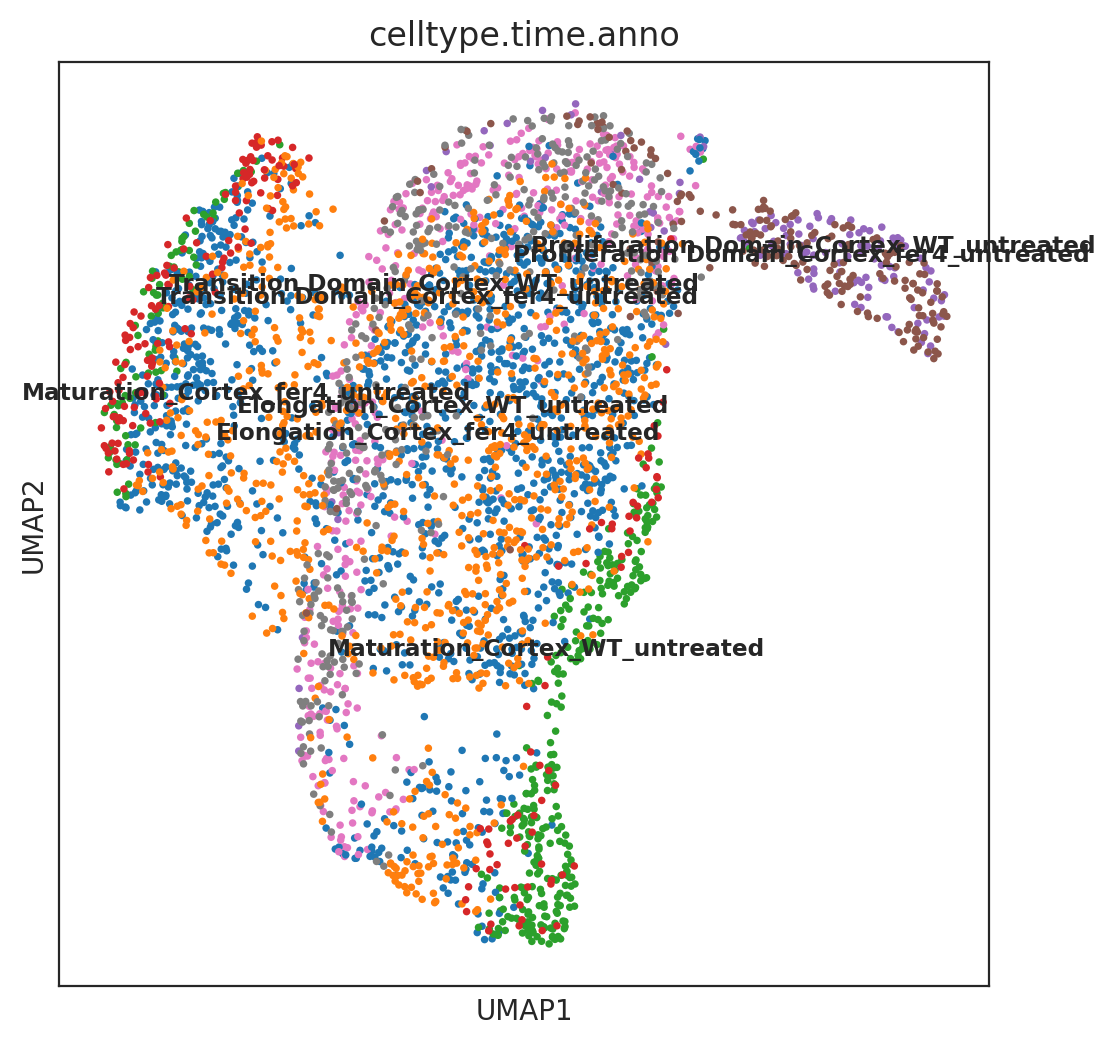

Instantiate Oracle object
Instantiate Oracle object
4187 genes were found in the adata. Note that Celloracle is intended to use around 1000-3000 genes, so the behavior with this number of genes may differ from what is expected.
KNN computation
cell number is :4094
Auto-selected k is :102
GRN construction


  0%|          | 0/8 [00:00<?, ?it/s]

Inferring GRN for Elongation_Cortex_WT_untreated...


  0%|          | 0/4169 [00:00<?, ?it/s]

Inferring GRN for Elongation_Cortex_fer4_untreated...


  0%|          | 0/4169 [00:00<?, ?it/s]

... (15 outputs left out)

Loading required package: igraph

Attaching package: ‘igraph’

The following objects are masked from ‘package:stats’:

    decompose, spectrum

The following object is masked from ‘package:base’:

    union

Loading required package: RColorBrewer

Welcome to linkcomm version 1.0-14

For a step-by-step guide to using linkcomm functions:
   > vignette(topic = "linkcomm", package = "linkcomm")
To run an interactive demo:
   > demo(topic = "linkcomm", package = "linkcomm")
To cite, see:
   > citation("linkcomm")
NOTE: To use linkcomm, you require read and write permissions in the current directory (see: help("getwd"), help("setwd"))



checking R library installation: linkcomm -> OK
checking R library installation: rnetcarto -> OK
processing... batch 1/1



Attaching package: ‘igraph’

The following objects are masked from ‘package:stats’:

    decompose, spectrum

The following object is masked from ‘package:base’:

    union

Loading required package: RColorBrewer

Attaching package: ‘igraph’

The following objects are masked from ‘package:stats’:

    decompose, spectrum

The following object is masked from ‘package:base’:

    union

Loading required package: RColorBrewer

Welcome to linkcomm version 1.0-14

For a step-by-step guide to using linkcomm functions:
   > vignette(topic = "linkcomm", package = "linkcomm")
To run an interactive demo:
   > demo(topic = "linkcomm", package = "linkcomm")
To cite, see:
   > citation("linkcomm")
NOTE: To use linkcomm, you require read and write permissions in the current directory (see: help("getwd"), help("setwd"))


Welcome to linkcomm version 1.0-14

For a step-by-step guide to using linkcomm functions:
   > vignette(topic = "linkcomm", package = "linkcomm")
To run an interactive demo:
   > d

Elongation_Cortex_WT_untreated: finished.
Elongation_Cortex_fer4_untreated: finished.
Maturation_Cortex_WT_untreated: finished.
Maturation_Cortex_fer4_untreated: finished.
Proliferation Domain_Cortex_WT_untreated: finished.
Proliferation Domain_Cortex_fer4_untreated: finished.
Transition Domain_Cortex_WT_untreated: finished.
Transition Domain_Cortex_fer4_untreated: finished.
Save Links object
Save merged score
Save network
Processing endodermis
Clusters for endodermis: ['Elongation_Endodermis' 'Maturation_Endodermis'
 'Transition Domain_Endodermis' 'Proliferation Domain_Endodermis']
Number of genes : 4604
View of AnnData object with n_obs × n_vars = 4038 × 4604
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spliced_RNA', 'nFeature_spliced_RNA', 'nCount_unspliced_RNA', 'nFeature_unspliced_RNA', 'percent.mt', 'percent.cp', 'nCount_SCT', 'nFeature_SCT', 'pANN_0.25_0.15_526', 'DF.classifications_0.25_0.15_526', 'SCT_snn_res.0.5', 'seurat_clusters', 'predicted.id', 'prediction

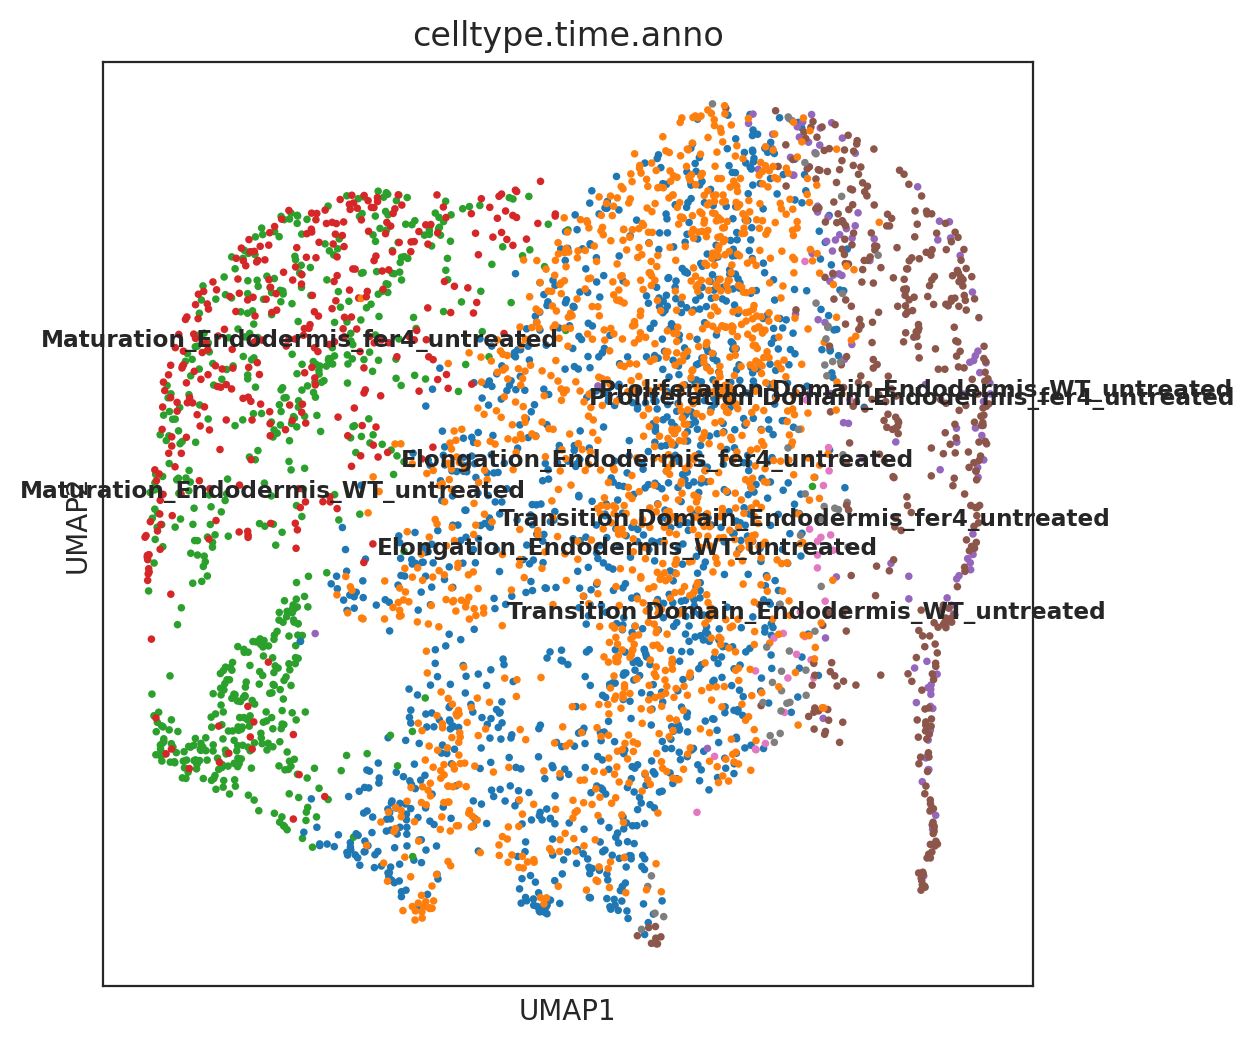

Instantiate Oracle object
Instantiate Oracle object
4604 genes were found in the adata. Note that Celloracle is intended to use around 1000-3000 genes, so the behavior with this number of genes may differ from what is expected.
KNN computation
cell number is :4038
Auto-selected k is :100
GRN construction


  0%|          | 0/8 [00:00<?, ?it/s]

Inferring GRN for Elongation_Endodermis_WT_untreated...


  0%|          | 0/4598 [00:00<?, ?it/s]

Inferring GRN for Elongation_Endodermis_fer4_untreated...


  0%|          | 0/4598 [00:00<?, ?it/s]

... (17 outputs left out)


Attaching package: ‘igraph’

The following objects are masked from ‘package:stats’:

    decompose, spectrum

The following object is masked from ‘package:base’:

    union

Loading required package: RColorBrewer

Welcome to linkcomm version 1.0-14

For a step-by-step guide to using linkcomm functions:
   > vignette(topic = "linkcomm", package = "linkcomm")
To run an interactive demo:
   > demo(topic = "linkcomm", package = "linkcomm")
To cite, see:
   > citation("linkcomm")
NOTE: To use linkcomm, you require read and write permissions in the current directory (see: help("getwd"), help("setwd"))


Attaching package: ‘igraph’

The following objects are masked from ‘package:stats’:

    decompose, spectrum

The following object is masked from ‘package:base’:

    union

Loading required package: RColorBrewer

Welcome to linkcomm version 1.0-14

For a step-by-step guide to using linkcomm functions:
   > vignette(topic = "linkcomm", package = "linkcomm")
To run an interactive demo:
   > d

Elongation_Endodermis_WT_untreated: finished.
Elongation_Endodermis_fer4_untreated: finished.


finished


Maturation_Endodermis_WT_untreated: finished.
Maturation_Endodermis_fer4_untreated: finished.
Proliferation Domain_Endodermis_WT_untreated: finished.
Proliferation Domain_Endodermis_fer4_untreated: finished.
Transition Domain_Endodermis_WT_untreated: finished.
Transition Domain_Endodermis_fer4_untreated: finished.
Save Links object
Save merged score
Save network
Processing trichoblast
Clusters for trichoblast: ['Elongation_Trichoblast', 'Proliferation Domain_Trichoblast', 'Maturation_Trichoblast', 'Transition Domain_Trichoblast']
Number of genes : 3523
View of AnnData object with n_obs × n_vars = 6944 × 3523
    obs: 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'nCount_spliced_RNA', 'nFeature_spliced_RNA', 'nCount_unspliced_RNA', 'nFeature_unspliced_RNA', 'percent.mt', 'percent.cp', 'nCount_SCT', 'nFeature_SCT', 'pANN_0.25_0.15_526', 'DF.classifications_0.25_0.15_526', 'SCT_snn_res.0.5', 'seurat_clusters', 'predicted.id', 'prediction.score.Transition.Domain_Atrichoblast', 'prediction.sc

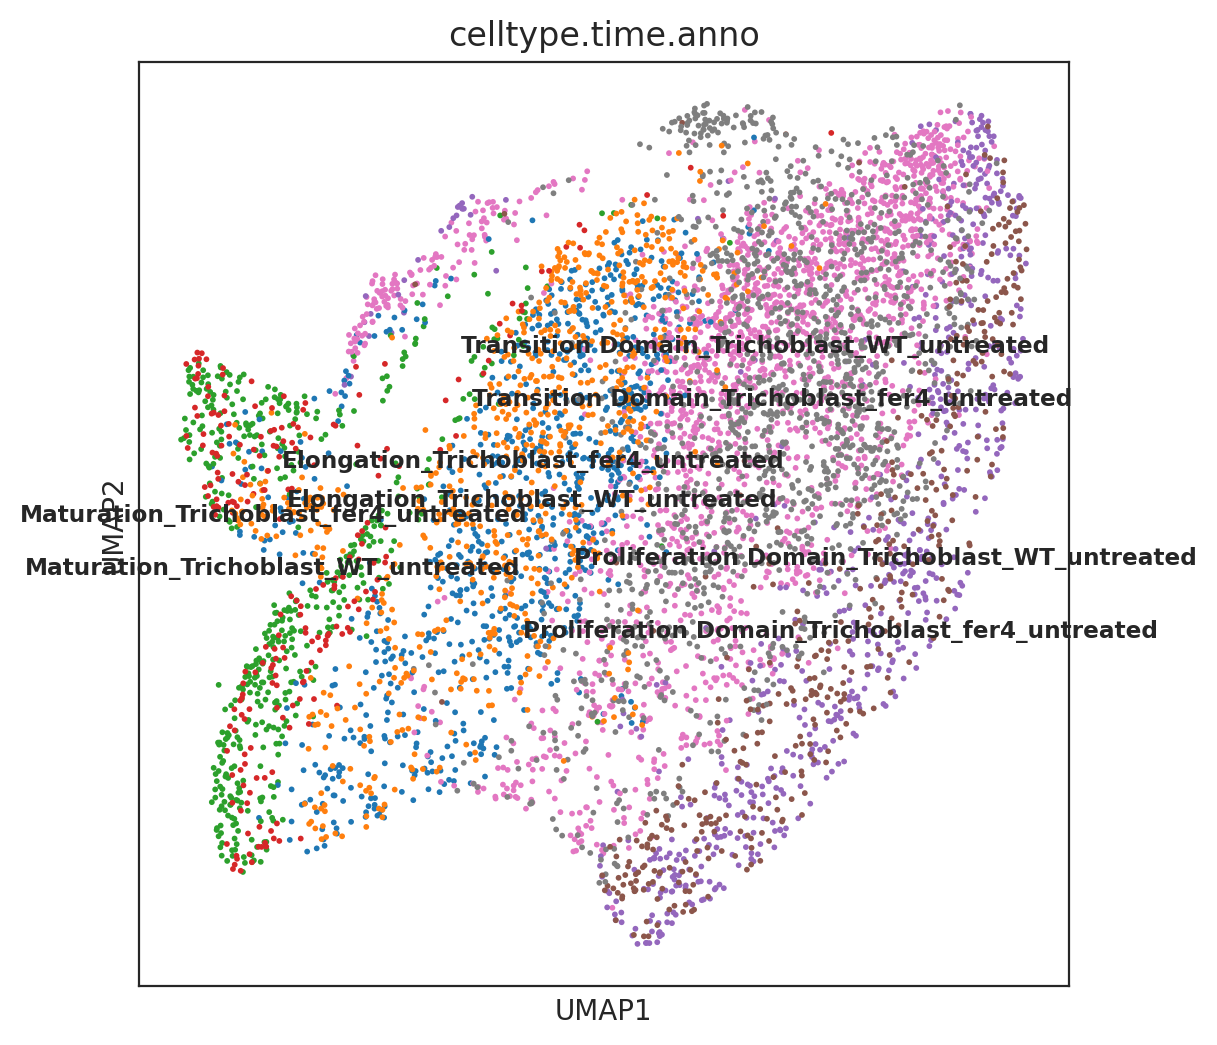

Instantiate Oracle object
Instantiate Oracle object
KNN computation
cell number is :6944
Auto-selected k is :173
GRN construction


  0%|          | 0/8 [00:00<?, ?it/s]

Inferring GRN for Elongation_Trichoblast_WT_untreated...


  0%|          | 0/3507 [00:00<?, ?it/s]

Inferring GRN for Elongation_Trichoblast_fer4_untreated...


  0%|          | 0/3507 [00:00<?, ?it/s]

... (6 outputs left out)

Inferring GRN for Proliferation Domain_Trichoblast_fer4_untreated...


  0%|          | 0/3507 [00:00<?, ?it/s]

Inferring GRN for Transition Domain_Trichoblast_WT_untreated...


  0%|          | 0/3507 [00:00<?, ?it/s]

In [ ]:
# Runs CellOracle through all the cell types
# Don't change anything here
for x in celltypes.keys():
    print(f"Processing {x}")

    # First, subset the DE enes based on the current cluster/cell type
    # Special cases for lrc and trichoblast, so have to process them separately 
    if x == 'lrc':
        # Search for 'lateral root cap' in the cluster
        my_cluster = DE['cluster_id'][DE['cluster_id'].str.contains("lateral root cap", case=False, na=False)].unique()
        
    elif x == 'trichoblast':
        # Exclude any clusters containing 'atrichoblast' for 'trichoblast'
        my_cluster = DE['cluster_id'][DE['cluster_id'].str.contains(x, case=False, na=False)].unique()
        my_cluster = [cluster for cluster in my_cluster if 'atrichoblast' not in cluster.lower()]
        
    else:
        # All other celltypes
        my_cluster = DE['cluster_id'][DE['cluster_id'].str.contains(x, case=False, na=False)].unique()

    print(f"Clusters for {x}: {my_cluster}")
    
    # Subset the genes
    gene_of_interest = ADATA.var.index[ADATA.var.index.isin(wanted_TFs['GeneID']) |
                                      ADATA.var.index.isin(DE[DE['cluster_id'].isin(my_cluster)]['gene'].unique())]

    print('Number of genes : '+format(len(gene_of_interest)))

    # Subset the original AnnData object (ADATA) to include only cells of type 'x' and selected genes  
    adata = ADATA[celltypes[x], gene_of_interest]
    print(adata)

    # Perform Principal Component Analysis (PCA) to reduce dimensionality
    sc.pp.pca(adata)
    # Compute the k-nearest neighbors (KNN) graph for downstream clustering and visualization  
    sc.pp.neighbors(adata)
    # Compute the UMAP
    sc.tl.umap(adata)
    # Set the figure size for the UMAP plot  
    plt.rcParams["figure.figsize"] = [6, 6]
    # Plot the UMAP, coloring cells based on 'celltype.time.anno', with the legend displayed on the plot  
    sc.pl.umap(adata, color=['celltype.time.anno'], legend_loc='on data', legend_fontsize='small')
    # Rename the '_index' column in the raw AnnData object to 'features'  
    adata.__dict__['_raw'].__dict__['_var'] = adata.__dict__['_raw'].__dict__['_var'].rename(columns={'_index': 'features'})
    # Save the processed AnnData object to an HDF5 file with a name based on the cell type 'x'  
    adata.write_h5ad(x+'_rawRNA_celloracle.h5ad')
    
    print('Instantiate Oracle object')
    # Create an instance of the Oracle class from CellOracle
    oracle = co.Oracle()

    # In this notebook, we use raw RNA values as an input of Oracle object
    # Assign the raw RNA count values to `adata.X` from the 'raw_count' layer  
    # This ensures that Oracle receives the unnormalized count data for analysis  
    adata.X = adata.layers["raw_count"].copy()

    print('Instantiate Oracle object')
    # Import the AnnData object into the Oracle instance  
    # - `cluster_column_name="celltype.time.anno"` specifies the metadata column containing cell type annotations  
    # - `embedding_name="X_umap"` tells Oracle to use the UMAP embedding for visualization  
    oracle.import_anndata_as_raw_count(adata=adata, cluster_column_name="celltype.time.anno",embedding_name="X_umap")
    
    # Import the TF regulatory network data into Oracle  
    # This provides a dictionary mapping target genes (TG) to transcription factors (TF)  
    oracle.import_TF_data(TFdict=TG_to_TF_dictionary)
    
    print('KNN computation')
    # Perform Principal Component Analysis (PCA) on the Oracle object 
    oracle.perform_PCA()
    # Determine the optimal number of principal components to use  
    # - `np.cumsum(oracle.pca.explained_variance_ratio_)` computes the cumulative explained variance  
    # - `np.diff()` calculates the change in variance between consecutive components  
    # - The condition `> 0.002` finds the point where the increase in explained variance becomes insignificant  
    n_comps = np.where(np.diff(np.diff(np.cumsum(oracle.pca.explained_variance_ratio_))>0.002))[0][0]
    # Set an upper limit of 50 principal components to prevent overfitting
    n_comps = min(n_comps, 50)
    # Get the total number of cells in the dataset
    n_cell = oracle.adata.shape[0]
    # Print the total number of cells  
    print(f"cell number is :{n_cell}")
    # Determine the value of `k` for KNN based on 2.5% of the total cell count 
    k = int(0.025*n_cell)
    # Print the automatically selected k value  
    print(f"Auto-selected k is :{k}")
    # Perform KNN imputation to reconstruct missing values and refine the data structure  
    # - `n_pca_dims=n_comps`: Use the determined number of PCA components  
    # - `k=k`: Set the number of neighbors based on the calculated value  
    # - `balanced=True`: Ensures balanced neighborhood selection  
    # - `b_sight=k*8`: Defines the search space for nearest neighbors  
    # - `b_maxl=k*4`: Limits the number of connections  
    # - `n_jobs=8`: Utilizes four CPU cores for parallel computation  
    oracle.knn_imputation(n_pca_dims=n_comps, k=k, balanced=True, b_sight=k*8, b_maxl=k*4, n_jobs=12)
    
    print('GRN construction')
    # Construct gene regulatory network (GRN) using the Oracle object
    # Generate regulatory links for GRN based on cell-type annotations.  
    # 'alpha' controls the sparsity of the network, 'verbose_level' determines the logging detail, and 'test_mode' runs a test if True.  
    links = oracle.get_links(cluster_name_for_GRN_unit="celltype.time.anno", alpha=10, verbose_level=10, test_mode=False)
    
    print('Save Links object')
    # Save the links object as an HDF5 file for later use.  
    links.to_hdf5(file_path=x+"_rawRNA.links.celloracle.links")
    
    print('Filter Links')
    # Filter links based on statistical significance (p-value < 0.01),  
    # absolute coefficient weight, and keep only the top 20,000 strongest links.  
    links.filter_links(p=0.01, weight="coef_abs", threshold_number=20000)
    
    print('Calculate network scores. It takes several minutes')
    # Calculate scores for each regulatory interaction in the network.
    links.get_score()
    # Display the first few rows of the merged score table to check results.
    links.merged_score.head()
    
    print('Save Links object')
    # Save the filtered links with a threshold applied  
    links.to_hdf5(file_path=x+"_rawRNA_p01_20k.links.celloracle.links")
    
    print('Save merged score')
    # Extract and save the final gene regulatory network scores. Store the merged scores in res
    res = links.merged_score

    # Initialize an empty list to store gene names.  
    name = []
    # Convert gene IDs into gene names using the id2name mapping.  
    for i in res.index.values:
        name.append(id2name[1][np.where(id2name[0]==i)[0]].tolist()[0])
    # Insert the gene names as the first column in the results dataframe.  
    res.insert(0, 'name', name)
    # Save the final gene regulatory network scores as a CSV file.  
    res.to_csv(x+"_rawRNA_celloracle_gene_score_iGRN.csv")

    # Initialize an empty DataFrame to store network data. 
    df = pd.DataFrame()
    # Initialize an empty list to store cluster labels.
    cluster = []
    
    print('Save network')
    for i in links.links_dict.keys():
        # Append the filtered links for each cluster to the DataFrame. 
        df = df.append(links.filtered_links[i])
        # Extend the cluster list with repeated values of the current cluster name,  
        # ensuring each row gets assigned the correct cluster label (assuming 20,000 links per cluster).  
        cluster.extend(np.repeat(i, 20000).tolist())

    # Assign the cluster labels to the DataFrame.
    df['cluster'] = cluster
    # Reorder and select relevant columns for the final output.  
    df = df[['source', 'target', 'cluster', 'coef_mean', 'coef_abs', 'p', '-logp']]

    # Initialize an empty list to store source gene names.  
    name = []
    # Convert source gene IDs into gene names using the id2name mapping
    for i in df['source']:
        name.append(id2name[1][np.where(id2name[0]==i)[0]].tolist()[0])
    # Insert the source gene names as the second column in the DataFrame. 
    df.insert(1, 'source_name', name)

    # Reinitialize the list to store target gene names.  
    name = []
    # Convert target gene IDs into gene names using the id2name mapping.
    for i in df['target']:
        name.append(id2name[1][np.where(id2name[0]==i)[0]].tolist()[0])
    # Insert the target gene names as the fourth column in the DataFrame. 
    df.insert(3, 'target_name', name)
    # Save the final gene regulatory network data as a CSV file.  
    df.to_csv(x+"_rawRNA_celloracle_network_iGRN.csv")
    